# SUIM-Net RSB

This notebook evaluates the SUIM-Net RSB model from the original SUIM paper on our test set. The model code and the pretrained weights come from the original SUIM project and the data loading and evaluation follow our U-Net notebook.

The 5 classes are robots, fish, divers, reefs and wrecks. Water, plants and sea-floor are counted as background.

The results in this notebook comes from `MODE = 'pretrained'`. This mode loads the authors weights and only runs the evaluation, so no training happens here.

The notebook can also train the model (`MODE = 'train'`) with the following setup:
- Normalization: the image pixels are divided by 255.
- Augmentation: each image and its mask receive the same random changes.
- Batch normalization: already part of the RSB model.
- Learning rate schedule: the learning rate is halved every 10 epochs.
- Adam optimizer: starts with a learning rate of 1e-4.

The training mode differs slightly from the original training script: batch size 2 instead of 8, a separate validation split, one pass over the training images per epoch instead of 5,000 batches, and the learning rate schedule. A model trained here would therefore not be an exact reproduction of the paper's training.

## Connect to Drive

`SUIM_RSB_data.zip` has to be in My Drive (still zipped). It has the cleaned training data, the test data and the original RSB weights. This cell connects Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Imports

This cell also prints the library versions and checks that a GPU is available. This notebook was ran in Colab.

In [ ]:
import hashlib
import json
import math
import os
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_dilation
from IPython.display import display
try:
    import tensorflow as tf
except ImportError as error:
    raise ImportError('Use a Colab TensorFlow runtime, or install requirements-suim-rsb.txt in Python 3.12.') from error
from tensorflow import keras
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (Conv2D, UpSampling2D, MaxPooling2D,
    BatchNormalization, Activation, add, Lambda, Concatenate, ZeroPadding2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
from datetime import datetime, timezone
import zipfile
import shutil
import time

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Settings

`MODE` decides what the notebook does:

- `smoke`: one epoch on 4 training images, just to check that everything works
- `train`: trains a new model for 50 epochs
- `pretrained`: loads the authors weights and only evaluates them (this method was used for the results below)
- `checkpoint`: evaluates a saved model from `CUSTOM_WEIGHTS`

Each run is saved to a new folder in My Drive / SUIM_RSB_runs.

In [ ]:
MODE = 'pretrained'  # 'smoke', 'train', 'pretrained', or 'checkpoint'
DATA_ZIP = Path('/content/drive/MyDrive/SUIM_RSB_data.zip')
ROOT = Path('/content/suim_rsb_data')
RUNS_DIR = Path('/content/drive/MyDrive/SUIM_RSB_runs')
CUSTOM_WEIGHTS = None  # for checkpoint mode: Path('/content/drive/MyDrive/.../best.weights.h5')

WIDTH, HEIGHT = 320, 240  # original RSB input size, don't change
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 1e-4
MIN_LEARNING_RATE = 1e-6
LR_DROP_EVERY = 10
LR_DROP_FACTOR = 0.5
VALIDATION_FRACTION = 0.2
SEED = 42
PREDICTION_THRESHOLD = 0.5
MAX_TEST_IMAGES = None  # None = all 110 test images
USE_AUGMENTATION = True
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']
AUGMENTATION = dict(rotation_range=0.2, width_shift_range=0.05,
                    height_shift_range=0.05, shear_range=0.05, zoom_range=0.05,
                    horizontal_flip=True, fill_mode='nearest')

if MODE not in {'smoke', 'train', 'pretrained', 'checkpoint'}:
    raise ValueError('Choose smoke, train, pretrained, or checkpoint.')
if (WIDTH, HEIGHT) != (320, 240):
    raise ValueError('This adaptation keeps the original RSB size: 320 x 240.')
if not 0 < VALIDATION_FRACTION < 1 or BATCH_SIZE < 1 or EPOCHS < 1:
    raise ValueError('Invalid split, batch size, or epoch count.')
if MAX_TEST_IMAGES is not None and (not isinstance(MAX_TEST_IMAGES, int) or MAX_TEST_IMAGES < 1):
    raise ValueError('MAX_TEST_IMAGES must be None or a positive integer.')
keras.utils.set_random_seed(SEED)
EVALUATE_TEST = MODE != 'smoke'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '_' + MODE
RUN_DIR = RUNS_DIR / RUN_ID
OUTPUT_DIR = RUN_DIR / 'predictions'
CKPT_DIR = RUN_DIR / 'checkpoints'
BEST_WEIGHTS = CKPT_DIR / 'best.weights.h5'
TRAIN_DIR = ROOT / 'cleaned_suim/train_val'
TEST_DIR = ROOT / 'TEST'
PRETRAINED_WEIGHTS = ROOT / 'Checkpoint_Data/suimnet_rsb5.hdf5'
print('Mode:', MODE)
print('Results will be saved to:', RUN_DIR)
if not tf.config.list_physical_devices('GPU'):
    print('No GPU detected. Select a GPU runtime before the full training run.')

Mode: pretrained
Results will be saved to: /content/drive/MyDrive/SUIM_RSB_runs/20261116T184214_671280Z_pretrained


## Unzip the dataset

(The data is first unzipped to Colab's local storage. The results are still saved to Drive.)

In [ ]:
if not DATA_ZIP.is_file():
    raise FileNotFoundError('Upload SUIM_RSB_data.zip to the top level of My Drive first.')
archive_stamp = {'size': DATA_ZIP.stat().st_size, 'mtime': DATA_ZIP.stat().st_mtime}
marker = ROOT / '.extracted.json'
if not marker.is_file() or json.loads(marker.read_text()) != archive_stamp:
    if ROOT.exists():
        raise RuntimeError('Existing local extraction differs or is incomplete. Restart the Colab session and run again.')
    ROOT.mkdir(parents=True)
    with zipfile.ZipFile(DATA_ZIP) as archive:
        for item in archive.infolist():
            target = (ROOT / item.filename).resolve()
            if not target.is_relative_to(ROOT.resolve()):
                raise ValueError('Unsafe archive path: ' + item.filename)
        archive.extractall(ROOT)
    marker.write_text(json.dumps(archive_stamp))
if (ROOT / 'cleaned_suim/INCOMPLETE').exists():
    raise RuntimeError('The cleaned dataset is marked incomplete.')
if not (TRAIN_DIR / 'images').is_dir() or not (TEST_DIR / 'images').is_dir():
    raise FileNotFoundError('ZIP must contain cleaned_suim/train_val and TEST.')
RUN_DIR.mkdir(parents=True, exist_ok=False)
OUTPUT_DIR.mkdir()
CKPT_DIR.mkdir()
print('Data ready:', ROOT)

Data ready: /content/suim_rsb_data


## Prepare the data and split it

The images are matched with their masks by filename and the mask colors are converted into 5 class channels. RGB values above 127.5 count as 1, as in the original code, so masks with slightly off colors do still work.

The train/val split is about 80/20 with seed 42. Identical image files always stay in the same split, so exact duplicates cannot end up in both. (The split is saved so it can be checked later.)

TEST is kept separate and is only used for the final evaluation.

In [ ]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def index_files(folder, extensions):
    files = {}
    for path in sorted(Path(folder).iterdir()):
        if path.is_file() and path.suffix.lower() in extensions:
            if path.stem in files:
                raise ValueError(f'Ambiguous stem: {folder / path.stem}')
            files[path.stem] = path
    return files


# (image size, mask size) of the masks that are taller than their image
REVIEWED_CROPS = {
    'f_r_1058_': ((590, 375), (590, 430)),
    'f_r_1068_': ((590, 375), (590, 430)),
    'f_r_1069_': ((590, 375), (590, 430)),
    'f_r_1070_': ((590, 375), (590, 430)),
    'f_r_1133_': ((590, 375), (590, 430)),
    'f_r_1142_': ((590, 375), (590, 430)),
    'f_r_1151_': ((590, 375), (590, 430)),
    'f_r_1154_': ((590, 375), (590, 430)),
    'f_r_1214_': ((590, 375), (590, 430)),
    'f_r_1233_': ((590, 375), (590, 430)),
    'f_r_1259_': ((910, 435), (910, 490)),
    'f_r_1289_': ((590, 375), (590, 430)),
    'f_r_1290_': ((910, 435), (910, 490)),
    'f_r_1302_': ((590, 375), (590, 430)),
    'f_r_1318_': ((590, 375), (590, 430)),
    'f_r_1394_': ((910, 435), (910, 490)),
    'f_r_1424_': ((590, 375), (590, 430)),
    'f_r_1491_': ((590, 375), (590, 430)),
    'f_r_1515_': ((590, 375), (590, 430)),
    'f_r_1570_': ((910, 435), (910, 490)),
    'f_r_1779_': ((590, 375), (590, 430)),
    'f_r_1812_': ((910, 435), (910, 490)),
    'f_r_1816_': ((590, 375), (590, 430)),
    'f_r_1866_': ((590, 375), (590, 430)),
    'f_r_1879_': ((590, 375), (590, 430)),
    'f_r_401_': ((910, 435), (910, 490)),
    'f_r_829_': ((590, 375), (590, 430)),
    'f_r_921_': ((590, 375), (590, 430)),
    'f_r_934_': ((590, 375), (590, 430)),
    'f_r_968_': ((590, 375), (590, 430)),
    'f_r_991_': ((590, 375), (590, 430)),
    'w_r_1_': ((590, 375), (590, 430)),
    'w_r_24_': ((590, 375), (590, 430)),
    'w_r_25_': ((590, 375), (590, 430)),
    'w_r_27_': ((590, 375), (590, 430)),
    'w_r_47_': ((590, 375), (590, 430)),
    'w_r_7_': ((590, 375), (590, 430)),
}


def read_rgb_pair(stem, images, masks, size):
    with Image.open(images[stem]) as source:
        image = source.convert('RGB')
    with Image.open(masks[stem]) as source:
        mask = source.convert('RGB')
    reviewed = REVIEWED_CROPS.get(stem)
    if reviewed is not None and image.size != reviewed[0]:
        raise ValueError(f'{stem}: reviewed image dimensions changed')
    if image.size != mask.size:
        if reviewed != (image.size, mask.size):
            raise ValueError(f'{stem}: unreviewed mismatch {image.size} / {mask.size}')
        mask = mask.crop((0, 0, image.width, image.height))
    # the original loader also resizes with nearest-neighbor
    image = image.resize(size, Image.Resampling.NEAREST)
    mask = mask.resize(size, Image.Resampling.NEAREST)
    return np.asarray(image, dtype=np.float32), np.asarray(mask, dtype=np.float32)


def getRobotFishHumanReefWrecks(mask):
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])
    return np.all(np.asarray(mask)[..., None, :] == colors, axis=-1).astype(np.float32)


def processSUIMDataRFHW(image, mask):
    return np.asarray(image, dtype=np.float32) / 255.0, getRobotFishHumanReefWrecks(np.asarray(mask) > 127.5)


def grouped_split(images, validation_fraction, seed):
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    if len(groups) < 2:
        raise ValueError('At least two unique image groups are needed for a split')
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    n_validation = min(len(hashes) - 1, max(1, round(len(hashes) * validation_fraction)))
    validation_hashes = set(hashes[:n_validation])
    rows = [{'stem': stem, 'image_sha256': digest,
             'partition': 'validation' if digest in validation_hashes else 'train'}
            for digest, stems in sorted(groups.items()) for stem in stems]
    return pd.DataFrame(rows).sort_values('stem').reset_index(drop=True)

In [ ]:
train_images = index_files(TRAIN_DIR / 'images', {'.jpg', '.jpeg', '.png'})
train_masks = index_files(TRAIN_DIR / 'masks', {'.bmp', '.png'})
if not train_images or train_images.keys() != train_masks.keys():
    raise ValueError('Training images and RGB masks must pair exactly by stem')
split = grouped_split(train_images, VALIDATION_FRACTION, SEED)
assert split.groupby('image_sha256').partition.nunique().max() == 1
train_stems = split.loc[split.partition == 'train', 'stem'].tolist()
validation_stems = split.loc[split.partition == 'validation', 'stem'].tolist()

test_images = index_files(TEST_DIR / 'images', {'.jpg', '.jpeg', '.png'})
if not test_images:
    raise ValueError('No TEST images found')
ground_truth = {symbol: index_files(TEST_DIR / 'masks' / symbol, {'.bmp', '.png'}) for symbol in CLASSES}
for symbol, masks in ground_truth.items():
    if masks.keys() != test_images.keys():
        raise ValueError(f'TEST {symbol} masks do not pair exactly with TEST images')
selected_test_stems = sorted(test_images)
if MAX_TEST_IMAGES is not None:
    selected_test_stems = selected_test_stems[:MAX_TEST_IMAGES]
print(f'{len(train_stems)} training + {len(validation_stems)} validation pairs')
print(f'{len(selected_test_stems)}/{len(test_images)} TEST images selected')
print('Repeated-image groups:', int((split.groupby('image_sha256').size() > 1).sum()))
split.to_csv(RUN_DIR / 'split.csv', index=False)

1220 training + 305 validation pairs
110/110 TEST images selected
Repeated-image groups: 9


## Load batches and apply augmentation

The images are loaded a few at a time. During training, each image and its mask receive the same random rotation, shift, zoom or flip so they stay aligned. The augmentation settings come from `train_suimnet.py`. The masks use nearest-neighbor interpolation so their labels are not blurred.

The validation images are not augmented or shuffled. (None of this is used in pretrained mode.)

In [ ]:
class SUIMBatches(keras.utils.PyDataset):
    def __init__(self, stems, images, masks, batch_size, size, *, augment=False, shuffle=False):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=1)
        if not stems or batch_size < 1:
            raise ValueError('A nonempty stem list and positive batch size are required')
        self.stems, self.images, self.masks = tuple(stems), images, masks
        self.batch_size, self.size = batch_size, size
        self.augment, self.shuffle, self.epoch = augment, shuffle, 0
        self.order = np.arange(len(self.stems))
        self.image_aug = ImageDataGenerator(**AUGMENTATION, interpolation_order=1)
        self.mask_aug = ImageDataGenerator(**AUGMENTATION, interpolation_order=0)
        if shuffle:
            np.random.default_rng(SEED).shuffle(self.order)

    def __len__(self):
        return math.ceil(len(self.stems) / self.batch_size)

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError(index)
        xs, ys = [], []
        for position in self.order[index * self.batch_size:(index + 1) * self.batch_size]:
            image, mask = read_rgb_pair(self.stems[position], self.images, self.masks, self.size)
            if self.augment:
                params = self.image_aug.get_random_transform(image.shape, seed=SEED + self.epoch * len(self.stems) + int(position))
                image = self.image_aug.apply_transform(image, params)
                mask = self.mask_aug.apply_transform(mask, params)
            image, target = processSUIMDataRFHW(image, mask)
            xs.append(image)
            ys.append(target)
        return np.stack(xs), np.stack(ys)

    def on_epoch_end(self):
        self.epoch += 1
        if self.shuffle:
            np.random.default_rng(SEED + self.epoch).shuffle(self.order)

## Build SUIM-Net RSB

RSB stands for residual skip block.

The encoder extracts the image features and the decoder uses them to predict a mask for each class.

The architecture is the same as in `models/suim_net.py`, including the batch normalization layers. Only the imports, the model constructor and the Adam syntax were updated so that it works with the newer Keras version.

In pretrained mode this cell loads the authors' weights (`suimnet_rsb5.hdf5`). The model has 3.86M parameters.

In [ ]:
def RSB(input_tensor, kernel_size, filters, strides=1, skip=True):
    """
       A residual skip block
    """
    f1, f2, f3, f4 = filters
    ## sub-block1
    x = Conv2D(f1, (1, 1), strides=strides)(input_tensor)
    x = BatchNormalization(momentum=0.8)(x)
    x = Activation('relu')(x)
    ## sub-block2
    x = Conv2D(f2, kernel_size, padding='same')(x)
    x = BatchNormalization(momentum=0.8)(x)
    x = Activation('relu')(x)
    ## sub-block3
    x = Conv2D(f3, (1, 1))(x)
    x = BatchNormalization(momentum=0.8)(x)
    ## skip connetion based on the given choice
    if skip:
        shortcut = input_tensor
    else:
        shortcut = Conv2D(f4, (1, 1), strides=strides)(input_tensor)
        shortcut = BatchNormalization(momentum=0.8)(shortcut)
    ## complete connection and activation
    x = add([x, shortcut])
    x = Activation('relu')(x)
    return x


def Suim_Encoder_RSB(inp_res, channels=1):
    """
       SUIM-Net encoder
    """
    im_H, im_W = inp_res
    img_input = Input(shape=(im_H, im_W, channels))
    ## encoder block 1
    x = Conv2D(64, (5, 5), strides=1)(img_input)
    enc_1 = x
    ## encoder block 2
    x = BatchNormalization(momentum=0.8)(x)
    x = Activation('relu')(x)
    x = MaxPooling2D((3, 3) , strides=2)(x)
    x = RSB(x, 3, [64, 64, 128, 128], strides=2, skip=False)
    x = RSB(x, 3, [64, 64, 128, 128], skip=True)
    x = RSB(x, 3, [64, 64, 128, 128], skip=True)
    enc_2 = x
    ## encoder block 3
    x = RSB(x, 3, [128, 128, 256, 256], strides=2, skip=False)
    x = RSB(x, 3, [128, 128, 256, 256], skip=True)
    x = RSB(x, 3, [128, 128, 256, 256], skip=True)
    x = RSB(x, 3, [128, 128, 256, 256], skip=True)
    enc_3 = x
    ## return
    return img_input, [enc_1 , enc_2 , enc_3]


def Suim_Decoder_RSB(enc_inputs, n_classes):
    """
       SUIM-Net decoder
    """
    def concat_skip(layer_input, skip_input, filters, f_size=3):
        # for concatenation of the skip connections from encoders
        u = Conv2D(filters, kernel_size=f_size, strides=1, padding='same', activation='relu')(layer_input)
        u = BatchNormalization(momentum=0.8)(u)
        u = Concatenate()([u, skip_input])
        return u
    ## decoder block 1
    enc_1 , enc_2 , enc_3 = enc_inputs
    dec_1 = Conv2D(256, (3, 3), padding='same')(enc_3)
    dec_1 = BatchNormalization(momentum=0.8)(dec_1)
    dec_1 = UpSampling2D(size=2)(dec_1)
    # padding for matching dimenstions
    dec_1 = Lambda(lambda x : x[: , :-2 , :-2 , :  ] )(dec_1) # padding
    dec_1 = ZeroPadding2D((1,1))(dec_1)
    enc_2 = Lambda(lambda x : x[: , :-1 , :-1 , :  ] )(enc_2) # padding
    enc_2 = ZeroPadding2D((1,1))(enc_2)
    dec_1s = concat_skip(enc_2, dec_1, 256)
    ## decoder block 2
    dec_2 = Conv2D(256, (3, 3), strides=1, padding='same')(dec_1s)
    dec_2 = BatchNormalization(momentum=0.8)(dec_2)
    dec_2 = UpSampling2D(size=2)(dec_2)
    dec_2s = Conv2D(128, (3, 3), strides=1, padding='same')(dec_2)
    dec_2s = BatchNormalization(momentum=0.8)(dec_2s)
    dec_2s = UpSampling2D(size=2)(dec_2s)
    # padding for matching dimenstions
    enc_1 = ZeroPadding2D((2,2))(enc_1)
    dec_2s = concat_skip(enc_1, dec_2s, 128)
    ## decoder block 3
    dec_3 = Conv2D(128, (3, 3), padding='same')(dec_2s)
    dec_3 = BatchNormalization()(dec_3)
    dec_3s = Conv2D(64, (3, 3), padding='same')(dec_3)
    dec_3s = BatchNormalization(momentum=0.8)(dec_3s)
    ## return output layer
    out = Conv2D(n_classes, (3, 3), padding='same', activation='sigmoid')(dec_3s)
    return out


def build_suim_rsb():
    inputs, features = Suim_Encoder_RSB((HEIGHT, WIDTH), channels=3)
    outputs = Suim_Decoder_RSB(features, len(CLASSES))
    model = Model(inputs=inputs, outputs=outputs, name='suim_net_rsb')
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                  loss='binary_crossentropy', metrics=['binary_accuracy'])
    return model

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = build_suim_rsb()
WEIGHTS_PATH = None
if MODE in {'pretrained', 'checkpoint'}:
    WEIGHTS_PATH = PRETRAINED_WEIGHTS if MODE == 'pretrained' else CUSTOM_WEIGHTS
    if WEIGHTS_PATH is None or not Path(WEIGHTS_PATH).is_file():
        raise FileNotFoundError('Set CUSTOM_WEIGHTS to your saved checkpoint, or include the published RSB weights.')
    WEIGHTS_PATH = Path(WEIGHTS_PATH)
    model.load_weights(str(WEIGHTS_PATH))  # strict loading, no layers get skipped
    print('Loaded:', WEIGHTS_PATH)
else:
    print('Fresh weights. No published checkpoint is used for training.')
assert model.output_shape == (None, HEIGHT, WIDTH, len(CLASSES))
print('Parameters:', f'{model.count_params():,}')
print('Batch normalization layers:', sum(isinstance(layer, BatchNormalization) for layer in model.layers))
model.summary()

Loaded: /content/suim_rsb_data/Checkpoint_Data/suimnet_rsb5.hdf5
Parameters: 3,863,941
Batch normalization layers: 31


Model: "suim_net_rsb"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 240, 320,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 236, 316,  │      4,864 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 236, 316,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 236, 316,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 117, 157,  │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 59, 79,    │      4,160 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 59, 79,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 59, 79,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 59, 79,    │     36,928 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 59, 79,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 59, 79,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 59, 79,    │      8,320 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 59, 79,    │      8,320 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 59, 79,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 59, 79,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 59, 79,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 59, 79,    │          0 │ add[0][0]       

 Total params: 3,863,941 (14.74 MB)

 Trainable params: 3,854,981 (14.71 MB)

 Non-trainable params: 8,960 (35.00 KB)

## Train the model

This cell only does something in `smoke` and `train` mode. In pretrained mode it is skipped, which is why it prints `Evaluation mode: training skipped.` below.

For a full training run, Adam starts at 1e-4 and the learning rate is halved at epochs 11, 21, 31 and 41 (with a minimum of 1e-6). The weights with the lowest validation loss are saved to Drive and reloaded at the end.

In [ ]:
def scheduled_learning_rate(epoch, current_rate=None):
    return max(MIN_LEARNING_RATE, LEARNING_RATE * LR_DROP_FACTOR ** (epoch // LR_DROP_EVERY))

training_history = None
if MODE in {'smoke', 'train'}:
    active_train = train_stems[:4] if MODE == 'smoke' else train_stems
    active_validation = validation_stems[:2] if MODE == 'smoke' else validation_stems
    active_epochs = 1 if MODE == 'smoke' else EPOCHS
    training_batches = SUIMBatches(active_train, train_images, train_masks, BATCH_SIZE,
                                  (WIDTH, HEIGHT), augment=USE_AUGMENTATION, shuffle=True)
    validation_batches = SUIMBatches(active_validation, train_images, train_masks, BATCH_SIZE,
                                    (WIDTH, HEIGHT))
    example_images, example_targets = training_batches[0]
    assert example_images.shape[1:] == (HEIGHT, WIDTH, 3)
    assert example_targets.shape[1:] == (HEIGHT, WIDTH, len(CLASSES))
    assert np.isfinite(example_images).all() and 0 <= example_images.min() <= example_images.max() <= 1
    assert np.isin(example_targets, [0, 1]).all()
    assert np.all(example_targets.sum(axis=-1) <= 1)
    callbacks = [
        keras.callbacks.LearningRateScheduler(scheduled_learning_rate, verbose=1),
        keras.callbacks.ModelCheckpoint(str(BEST_WEIGHTS), monitor='val_loss',
            save_best_only=True, save_weights_only=True, mode='min', verbose=1),
        keras.callbacks.CSVLogger(str(CKPT_DIR / 'training_history.csv')),
        keras.callbacks.TerminateOnNaN(),
    ]
    training_started = time.perf_counter()
    history = model.fit(training_batches, validation_data=validation_batches,
                        epochs=active_epochs, callbacks=callbacks, shuffle=False)
    training_seconds = time.perf_counter() - training_started
    training_history = pd.DataFrame(history.history)
    if len(training_history) != active_epochs or not np.isfinite(training_history[['loss', 'val_loss']].to_numpy()).all():
        raise RuntimeError('Training did not finish with finite losses; do not report this run.')
    if not BEST_WEIGHTS.is_file():
        raise RuntimeError('No best checkpoint was saved.')
    model.load_weights(str(BEST_WEIGHTS))
    WEIGHTS_PATH = BEST_WEIGHTS
    training_history[['loss', 'val_loss']].plot(title='SUIM-Net RSB loss', xlabel='Epoch index (starts at 0)')
    plt.tight_layout()
    plt.savefig(CKPT_DIR / 'training_loss.png', dpi=140)
    plt.show()
    training_report = {
        'mode': MODE, 'reportable_experiment': MODE == 'train',
        'epochs_completed': len(training_history), 'train_images_used': len(active_train),
        'validation_images_used': len(active_validation), 'batch_size': BATCH_SIZE,
        'best_epoch': int(training_history.val_loss.argmin()) + 1,
        'best_val_loss': float(training_history.val_loss.min()), 'seconds': training_seconds,
        'weights': str(WEIGHTS_PATH), 'weights_sha256': file_sha256(WEIGHTS_PATH),
        'seed': SEED, 'augmentation': AUGMENTATION, 'augmentation_enabled': USE_AUGMENTATION,
        'normalization': 'RGB / 255', 'optimizer': 'Adam', 'batch_normalization': True,
        'learning_rate_schedule': [scheduled_learning_rate(e) for e in range(active_epochs)],
        'tensorflow': tf.__version__, 'keras': keras.__version__, 'numpy': np.__version__,
    }
    (RUN_DIR / 'training_summary.json').write_text(json.dumps(training_report, indent=2))
    if MODE == 'smoke':
        print('TRIAL PASSED. This is not a final model result. Set MODE to train and run all cells again for 50 epochs.')
else:
    print('Evaluation mode: training skipped.')

Evaluation mode: training skipped.


## Predict on the test images

The model predicts 5 masks for each of the 110 test images. The inputs are resized with bicubic interpolation and divided by 255, as in the U-Net notebook, predictions above 0.5 count as foreground.

In [ ]:
def predict_and_save(model, image_paths, stems, output_dir, size, batch_size, threshold):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for symbol in CLASSES:
        class_dir = output_dir / symbol
        class_dir.mkdir(exist_ok=True)
    for start in range(0, len(stems), batch_size):
        selected = stems[start:start + batch_size]
        images = []
        for stem in selected:
            with Image.open(image_paths[stem]) as source:
                image = source.convert('RGB').resize(size, Image.Resampling.BICUBIC)
            images.append(np.asarray(image, dtype=np.float32) / 255.0)
        probabilities = model(np.stack(images), training=False).numpy()
        if probabilities.shape != (len(selected), size[1], size[0], len(CLASSES)):
            raise ValueError(f'Unexpected model output shape: {probabilities.shape}')
        if not np.isfinite(probabilities).all():
            raise ValueError('Non-finite predictions')
        binary = probabilities > threshold
        for index, stem in enumerate(selected):
            for channel, symbol in enumerate(CLASSES):
                Image.fromarray(binary[index, ..., channel].astype(np.uint8) * 255).save(output_dir / symbol / f'{stem}.bmp')
        if start == 0 or start + batch_size >= len(stems) or (start + batch_size) % 20 == 0:
            print(f'Predicted {min(start + batch_size, len(stems))}/{len(stems)} images')
    return output_dir

In [ ]:
if EVALUATE_TEST:
    PREDICTION_DIR = predict_and_save(model, test_images, selected_test_stems, OUTPUT_DIR,
                                      (WIDTH, HEIGHT), INFERENCE_BATCH_SIZE, PREDICTION_THRESHOLD)
    pd.DataFrame({'stem': selected_test_stems,
                  'image_path': [str(test_images[s]) for s in selected_test_stems]}).to_csv(OUTPUT_DIR / 'test_images.csv', index=False)
else:
    print('TEST prediction skipped during trial.')

Predicted 1/110 images
Predicted 20/110 images
Predicted 40/110 images
Predicted 60/110 images
Predicted 80/110 images
Predicted 100/110 images
Predicted 110/110 images


## Evaluate the predictions

This is the same evaluation as in our U-Net notebook. IoU measures how much the predicted mask and the real mask overlap. The boundary F-score compares their edges, so it is not the same as pixel F1/Dice. An edge counts as matched if it is within 0.008 x the image diagonal of the other edge.

A class is only scored on the images where it appears in the ground truth, so false positives on images without that class do not change the average and the final score is the average of the 5 class scores.

In [ ]:
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius


def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    if seg.ndim != 2:
        raise ValueError('Expected a two-dimensional binary mask')
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary


def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    """
    Arguments:
        foreground_mask (ndarray): binary segmentation image.
        gt_mask         (ndarray): binary annotated image.
    Returns:
        P (float): boundaries precision
        R (float): boundaries recall
        F (float): boundaries F-measure
    """
    assert np.atleast_3d(foreground_mask).shape[2] == 1
    bound_pix = bound_th if bound_th >= 1 else \
                np.ceil(bound_th*np.linalg.norm(foreground_mask.shape))

    # Get the pixel boundaries of both masks
    fg_boundary = seg2bmap(foreground_mask);
    gt_boundary = seg2bmap(gt_mask);

    fg_dil = binary_dilation(fg_boundary,disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary,disk(int(bound_pix)))

    # Get the intersection
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil

    # Area of the intersection
    n_fg     = np.sum(fg_boundary)
    n_gt     = np.sum(gt_boundary)

    # Compute precision and recall
    if n_fg == 0 and  n_gt > 0:
        precision = 1
        recall = 0
    elif n_fg > 0 and n_gt == 0:
        precision = 0
        recall = 1
    elif n_fg == 0  and n_gt == 0:
        precision = 1
        recall = 1
    else:
        precision = np.sum(fg_match)/float(n_fg)
        recall    = np.sum(gt_match)/float(n_gt)

    # Compute F measure
    if precision + recall == 0:
        F = 0
    else:
        F = 2*precision*recall/(precision+recall);

    return precision, recall, F


def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0


def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.Resampling.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5


def evaluate_predictions(prediction_dir, ground_truth, stems, size):
    rows = []
    for symbol in CLASSES:
        predictions = index_files(prediction_dir / symbol, {'.bmp', '.png'})
        if set(predictions) != set(stems):
            raise ValueError(f'{symbol}: prediction stems differ from the selected TEST list')
        for stem in stems:
            real = read_and_bin(ground_truth[symbol][stem], size)
            generated = read_and_bin(predictions[stem], size)
            present = bool(real.any())
            precision, recall, f1 = db_eval_boundary(generated, real) if present else (np.nan,) * 3
            rows.append({'stem': stem, 'class': symbol, 'ground_truth_present': present,
                         'ground_truth_pixels': int(real.sum()), 'predicted_pixels': int(generated.sum()),
                         'boundary_precision': precision, 'boundary_recall': recall,
                         'boundary_f': f1, 'iou': IoU_bin(real, generated) if present else np.nan})
    per_image = pd.DataFrame(rows)
    class_rows = []
    for symbol in CLASSES:
        subset = per_image.loc[per_image['class'] == symbol]
        class_rows.append({'class': symbol, 'scored_images': int(subset.ground_truth_present.sum()),
                           'skipped_empty_gt_images': int((~subset.ground_truth_present).sum()),
                           'boundary_f_pct': 100 * subset.boundary_f.mean(), 'iou_pct': 100 * subset.iou.mean()})
    return per_image, pd.DataFrame(class_rows)

In [ ]:
if EVALUATE_TEST:
    per_image_metrics, class_metrics = evaluate_predictions(PREDICTION_DIR, ground_truth, selected_test_stems, (WIDTH, HEIGHT))
    per_image_metrics.to_csv(OUTPUT_DIR / 'per_image_metrics.csv', index=False)
    class_metrics.to_csv(OUTPUT_DIR / 'class_metrics.csv', index=False)
    display(class_metrics.round(2))

    def finite_or_none(value):
        return float(value) if np.isfinite(value) else None

    summary = {
        'mode': MODE, 'weights': str(WEIGHTS_PATH), 'weights_sha256': file_sha256(WEIGHTS_PATH),
        'training_directory': str(TRAIN_DIR), 'test_directory': str(TEST_DIR),
        'train_pairs': len(train_stems), 'validation_pairs': len(validation_stems),
        'test_images_evaluated': len(selected_test_stems), 'test_images_available': len(test_images),
        'partial_test': len(selected_test_stems) != len(test_images),
        'classes': CLASSES, 'image_size_width_height': [WIDTH, HEIGHT], 'threshold': PREDICTION_THRESHOLD,
        'seed': SEED, 'epochs_requested': EPOCHS if MODE == 'train' else 0,
        'macro_boundary_f_pct': finite_or_none(class_metrics.boundary_f_pct.mean()),
        'macro_iou_pct': finite_or_none(class_metrics.iou_pct.mean()),
        'classes_with_ground_truth': int((class_metrics.scored_images > 0).sum()),
        'metric_protocol': 'Per-image boundary F and binary IoU; skip empty GT per class; macro mean of class means',
        'training_protocol': 'Grouped seeded split; nearest masks; one pass per epoch; best validation-loss checkpoint',
        'tensorflow_version': tf.__version__, 'keras_version': keras.__version__, 'numpy_version': np.__version__,
        'model': 'SUIM-Net RSB',
        'source': 'SUIM-master.zip supplied by user; exact source hashes in notebook metadata',
    }
    (OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    print('Macro boundary F (%):', summary['macro_boundary_f_pct'])
    print('Macro IoU (%):', summary['macro_iou_pct'])
    print('PARTIAL TEST RUN' if summary['partial_test'] else 'Full TEST inventory evaluated')
    print('Saved predictions/split/metrics under:', OUTPUT_DIR)
else:
    print('TEST evaluation skipped during trial.')

,class,scored_images,skipped_empty_gt_images,boundary_f_pct,iou_pct
0,RO,12,98,72.69,63.90
1,FV,66,44,83.89,76.63
2,HD,42,68,89.02,81.20
3,RI,58,52,70.90,84.40
4,WR,27,83,57.50,77.20


Macro boundary F (%): 74.79980545009266
Macro IoU (%): 76.66535687891694
Full TEST inventory evaluated
Saved predictions/split/metrics under: /content/drive/MyDrive/SUIM_RSB_runs/20261116T184214_671280Z_pretrained/predictions


**Results** (all 110 test images):

| Class | Ours F | Paper F | Ours IoU | Paper IoU |
|---|---|---|---|---|
| Robots (RO) | 72.69 | 74.18 | 63.90 | 65.79 |
| Fish (FV) | 83.89 | 84.36 | 76.63 | 76.81 |
| Divers (HD) | 89.02 | 89.04 | 81.20 | 81.12 |
| Reefs (RI) | 70.90 | 71.92 | 84.40 | 84.90 |
| Wrecks (WR) | 57.50 | 65.37 | 77.20 | 80.68 |
| **Average** | **74.80** | 76.97 | **76.67** | 77.86 |

- With the authors' weights, the model reaches **74.80** boundary F and **76.67** IoU.
- Four of the five classes are within 2 points of the paper, so the reproduction is close. Wrecks are the only larger gap (57.50 vs 65.37 F).
- The paper reports 78.86 as its combined F score, but this is not the plain average of its per-class scores (which is 76.97). Our 74.80 is a plain average, so the actual gap is around 2 points.
- We are not too sure as to where the remaining gap comes from. Possible reasons are the newer TensorFlow/Keras version and small differences in the preprocessing.

## Score again without the overlapping images

Four of the TEST images are exact copies of images in the training data. The same predictions are scored again without them, so the results can also be reported on 106 images.

In [ ]:
if EVALUATE_TEST:
    # find the TEST images that are exact copies of a training image
    train_hashes = set(split.image_sha256)
    overlap_stems = sorted(s for s in selected_test_stems if file_sha256(test_images[s]) in train_hashes)
    print('TEST images that also appear in training:', overlap_stems)

    kept = per_image_metrics[~per_image_metrics.stem.isin(overlap_stems)]
    class_metrics_no_overlap = (kept.groupby('class', sort=False)
                                .agg(scored_images=('ground_truth_present', 'sum'),
                                     boundary_f_pct=('boundary_f', 'mean'), iou_pct=('iou', 'mean'))
                                .reset_index())
    class_metrics_no_overlap[['boundary_f_pct', 'iou_pct']] *= 100
    class_metrics_no_overlap.to_csv(OUTPUT_DIR / 'class_metrics_no_overlap.csv', index=False)
    display(class_metrics_no_overlap.round(2))

    summary['test_images_no_overlap'] = len(selected_test_stems) - len(overlap_stems)
    summary['overlap_stems'] = overlap_stems
    summary['macro_boundary_f_pct_no_overlap'] = float(class_metrics_no_overlap.boundary_f_pct.mean())
    summary['macro_iou_pct_no_overlap'] = float(class_metrics_no_overlap.iou_pct.mean())
    (OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    print(f"Without overlap ({summary['test_images_no_overlap']} images):")
    print('Macro boundary F (%):', summary['macro_boundary_f_pct_no_overlap'])
    print('Macro IoU (%):', summary['macro_iou_pct_no_overlap'])

TEST images that also appear in training: ['d_r_386_', 'n_l_0_', 'n_l_29_', 'n_l_87_']


,class,scored_images,boundary_f_pct,iou_pct
0,RO,10,72.74,66.65
1,FV,65,83.72,76.62
2,HD,39,88.56,80.70
3,RI,56,71.06,84.93
4,WR,26,56.31,76.58


Without overlap (106 images):
Macro boundary F (%): 74.48056313574133
Macro IoU (%): 77.09516695488408


- Without the four copied images, the scores are **74.48** boundary F and **77.10** IoU, which is almost the same as before (-0.32 F, +0.43 IoU).
- Robots only have 12 test images and 2 of them are copies, so this class changes the most.

## View an example

The ground truth masks (top row) and the predictions (bottom row) for the first test image. This is only one example, the scores above use all test images.

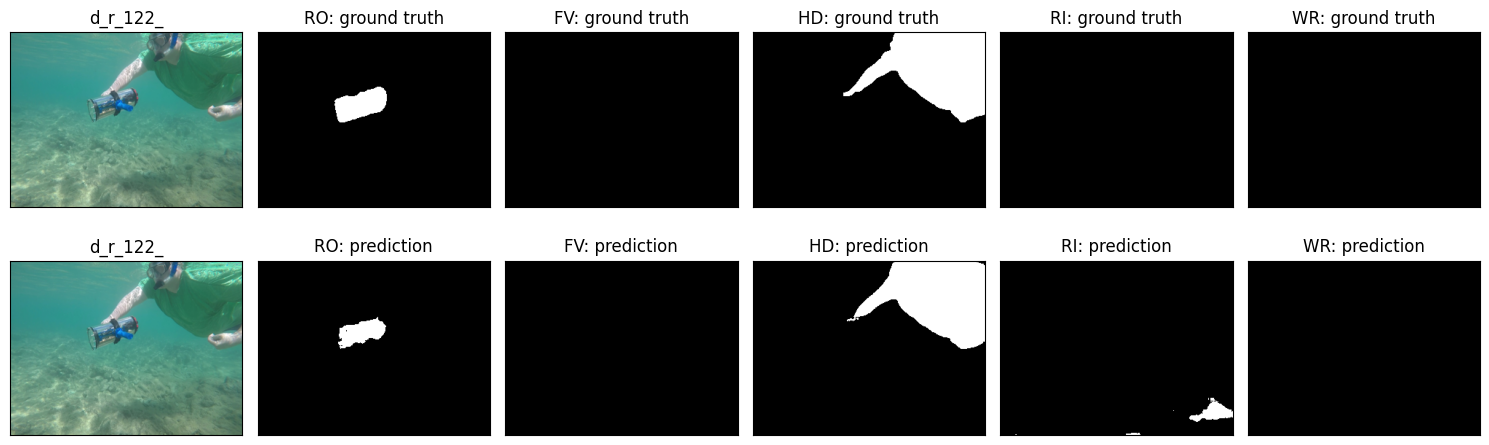

In [ ]:
if EVALUATE_TEST:
    stem = selected_test_stems[0]
    with Image.open(test_images[stem]) as source:
        image = source.convert('RGB').resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    for row in range(2):
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(stem)
    for channel, symbol in enumerate(CLASSES, start=1):
        axes[0, channel].imshow(read_and_bin(ground_truth[symbol][stem], (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
        axes[0, channel].set_title(f'{symbol}: ground truth')
        axes[1, channel].imshow(read_and_bin(PREDICTION_DIR / symbol / f'{stem}.bmp', (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
        axes[1, channel].set_title(f'{symbol}: prediction')
    for axis in axes.flat:
        axis.set_xticks([])
        axis.set_yticks([])
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'prediction_example.png', dpi=140)
    plt.show()
else:
    print('Trial finished. See the training summary above.')

## Sources

Model code: `models/suim_net.py` from the original SUIM project by Md Jahidul
Islam (2020). Data loading and evaluation: our group's `02_unet_baseline.ipynb`.
The boundary metric also uses code adapted from the
[DAVIS evaluator](https://github.com/fperazzi/davis).

[SUIM paper](https://arxiv.org/abs/2004.01241) ·
[Original project](https://github.com/xahidbuffon/SUIM-Net)

The original license is included below.

```text
MIT License

Copyright (c) [2020] [Md Jahidul Islam]

SUIM-Net: Semantic Segmentation of Underwater Imagery: Dataset and Benchmark
Paper: https://arxiv.org/pdf/2004.01241.pdf
Original repository: https://github.com/xahidbuffon/SUIM-Net

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```
